# DSA 4060 Week 3 Practical: A Simple Content-Based Recommender

**Student:** Iranzi Innocent
**Student number:** 670513
**Date:** 5 October 2026

## Objective

A small streaming platform wants to recommend movies from the genres a user has already liked. This lab stays with structured features. Each movie is a row of genre flags, and each user becomes a weighted mix of the genres in the movies they rated. TF-IDF and cosine similarity are left for Week 4.

The workflow is:

**Movie features → user preferences → recommendation scores → Top recommendations**

## 1. Import libraries

In [1]:
%matplotlib inline
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda value: f"{value:.6f}")

## 2. Create the movie dataset

The ten movies and five genre columns are the teaching table from the practical. A value of 1 means the genre is present. A value of 0 means it is absent. Galaxy Mission, for example, is Action and SciFi, so its item profile is `[1, 0, 0, 0, 1]`.

This notebook builds that table in code, then saves `movies.csv` after the extra movie has been added.

In [2]:
movies = pd.DataFrame({
    "movie_id": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    "title": [
        "Galaxy Mission", "Love in Nairobi", "Final Battle", "Family Weekend",
        "Future World", "Broken Hearts", "City Detectives", "Space Warriors",
        "Wedding Weekend", "Hidden Truth",
    ],
    "Action": [1, 0, 1, 0, 1, 0, 1, 1, 0, 0],
    "Comedy": [0, 0, 0, 1, 0, 0, 0, 0, 1, 0],
    "Drama": [0, 1, 0, 0, 0, 1, 1, 0, 0, 1],
    "Romance": [0, 1, 0, 0, 0, 1, 0, 0, 1, 0],
    "SciFi": [1, 0, 0, 0, 1, 0, 0, 1, 0, 0],
})
movies

,movie_id,title,Action,Comedy,Drama,Romance,SciFi
0,1,Galaxy Mission,1,0,0,0,1
1,2,Love in Nairobi,0,0,1,1,0
2,3,Final Battle,1,0,0,0,0
3,4,Family Weekend,0,1,0,0,0
4,5,Future World,1,0,0,0,1
5,6,Broken Hearts,0,0,1,1,0
6,7,City Detectives,1,0,1,0,0
7,8,Space Warriors,1,0,0,0,1
8,9,Wedding Weekend,0,1,0,1,0
9,10,Hidden Truth,0,0,1,0,0


## 3. Explore the dataset

| Column | Meaning |
| --- | --- |
| `movie_id` | Unique movie identifier |
| `title` | Movie title |
| Action, Comedy, Drama, Romance, SciFi | Binary structured features |

In [3]:
display(movies.head())
print("Shape:", movies.shape)
movies.info()

,movie_id,title,Action,Comedy,Drama,Romance,SciFi
0,1,Galaxy Mission,1,0,0,0,1
1,2,Love in Nairobi,0,0,1,1,0
2,3,Final Battle,1,0,0,0,0
3,4,Family Weekend,0,1,0,0,0
4,5,Future World,1,0,0,0,1


Shape: (10, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   movie_id  10 non-null     int64 
 1   title     10 non-null     object
 2   Action    10 non-null     int64 
 3   Comedy    10 non-null     int64 
 4   Drama     10 non-null     int64 
 5   Romance   10 non-null     int64 
 6   SciFi     10 non-null     int64 
dtypes: int64(6), object(1)
memory usage: 688.0+ bytes


The table has 10 movies and 7 columns. Five of those columns are genre features. One row is one movie: its identifier, its title, and the genres it does or does not have. No cell is missing, and every genre value is either 0 or 1.

## 4. Identify the structured features

The item-feature matrix is the block of genre columns. Later scores use only this block. The title is kept for display, not for the calculation.

In [4]:
features = ["Action", "Comedy", "Drama", "Romance", "SciFi"]
movie_features = movies[features]
movie_features

,Action,Comedy,Drama,Romance,SciFi
0,1,0,0,0,1
1,0,0,1,1,0
2,1,0,0,0,0
3,0,1,0,0,0
4,1,0,0,0,1
5,0,0,1,1,0
6,1,0,1,0,0
7,1,0,0,0,1
8,0,1,0,1,0
9,0,0,1,0,0


## 5. Create one item profile

The row for Galaxy Mission is the item profile used in the worked example.

In [5]:
movies.loc[movies["title"] == "Galaxy Mission"]

,movie_id,title,Action,Comedy,Drama,Romance,SciFi
0,1,Galaxy Mission,1,0,0,0,1


The 1s mark genres the movie has: Action and SciFi. The 0s mark genres it does not have: Comedy, Drama, and Romance. The recommender cannot see a plot, a cast, or a year. For this model, Galaxy Mission is only the vector `[1, 0, 0, 0, 1]`.

## 6. Create User A's ratings

User A has rated four movies. The ratings are explicit feedback on a 1 to 5 scale.

| Movie | Rating |
| --- | --- |
| Galaxy Mission | 5 |
| Love in Nairobi | 2 |
| Final Battle | 4 |
| Future World | 5 |

In [6]:
ratings = pd.DataFrame({
    "movie_id": [1, 2, 3, 5],
    "rating": [5, 2, 4, 5],
})
ratings

,movie_id,rating
0,1,5
1,2,2
2,3,4
3,5,5


## 7. Join the ratings to the movie features

The join attaches the genre flags to each movie the user has rated, so the rating and the item profile sit on the same row.

In [7]:
user_movies = ratings.merge(movies, on="movie_id")
user_movies

,movie_id,rating,title,Action,Comedy,Drama,Romance,SciFi
0,1,5,Galaxy Mission,1,0,0,0,1
1,2,2,Love in Nairobi,0,0,1,1,0
2,3,4,Final Battle,1,0,0,0,0
3,5,5,Future World,1,0,0,0,1


In [8]:
user_movies[["title", "rating", "Action", "Comedy", "Drama", "Romance", "SciFi"]]

,title,rating,Action,Comedy,Drama,Romance,SciFi
0,Galaxy Mission,5,1,0,0,0,1
1,Love in Nairobi,2,0,0,1,1,0
2,Final Battle,4,1,0,0,0,0
3,Future World,5,1,0,0,0,1


Before any weighting, User A looks like an Action and SciFi viewer. The two films rated 5, Galaxy Mission and Future World, are both Action and SciFi. Final Battle, rated 4, is Action only. Love in Nairobi is the exception: it is Drama and Romance, and the rating is only 2. Comedy does not appear in this history at all.

## 8. Build the user profile

### 8.1 Weight each rated movie by its rating

Multiplying a genre row by the rating makes a highly rated movie pull the profile harder than a weakly rated movie. A genre that is absent stays 0, so it adds nothing even when the rating is high.

In [9]:
rated_features = user_movies[features]
user_ratings = user_movies["rating"]
display(rated_features)
display(user_ratings)

weighted_features = rated_features.mul(user_ratings, axis=0)
weighted_features

,Action,Comedy,Drama,Romance,SciFi
0,1,0,0,0,1
1,0,0,1,1,0
2,1,0,0,0,0
3,1,0,0,0,1


0    5
1    2
2    4
3    5
Name: rating, dtype: int64

,Action,Comedy,Drama,Romance,SciFi
0,5,0,0,0,5
1,0,0,2,2,0
2,4,0,0,0,0
3,5,0,0,0,5


Galaxy Mission contributes 5 to Action and 5 to SciFi. Future World does the same. Final Battle contributes 4 to Action only. Love in Nairobi contributes 2 to Drama and 2 to Romance. The rating of 2 still adds to those genres. This model has no negative weight, so a low rating is a weak vote in favour, not a vote against.

### 8.2 Sum the weighted rows

The sum is the raw user profile: a total for each genre across the movies the user rated.

In [10]:
user_profile = weighted_features.sum()
user_profile

Action     14
Comedy      0
Drama       2
Romance     2
SciFi      10
dtype: int64

In [11]:
user_profile.sort_values(ascending=False)

Action     14
SciFi      10
Drama       2
Romance     2
Comedy      0
dtype: int64

Action totals 14 and SciFi totals 10. Those are the two strongest genres. Drama and Romance total 2 each, both from the single low rating of Love in Nairobi. Comedy totals 0 because no rated movie had that genre. The raw totals are not proportions yet: 14 means "14 rating-points landed on Action", not "the user is 14 times more interested in Action than in another genre" until the next step divides through by the total.

### 8.3 Normalize the profile

Dividing by the sum converts the totals into shares. The five shares add to 1, which makes two users comparable even when they used different rating scales or rated different numbers of movies.

Action    0.500000
Comedy    0.000000
Drama     0.071429
Romance   0.071429
SciFi     0.357143
dtype: float64

Profile sum: 1.0


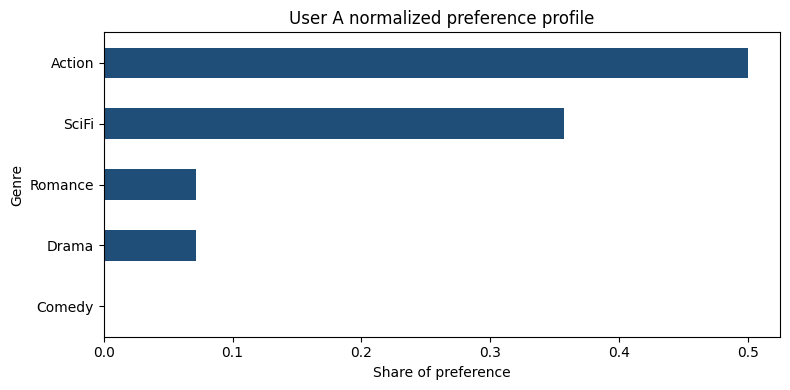

In [12]:
user_profile_normalized = user_profile / user_profile.sum()
display(user_profile_normalized)
print("Profile sum:", user_profile_normalized.sum())

ax = user_profile_normalized.sort_values().plot(
    kind="barh",
    color="#1F4E78",
    figsize=(8, 4),
    legend=False,
)
ax.set_title("User A normalized preference profile")
ax.set_xlabel("Share of preference")
ax.set_ylabel("Genre")
plt.tight_layout()
plt.show()

User A's two strongest preferences are Action, with share 0.500, and SciFi, with share 0.357. Together they are about 86% of the profile. Drama and Romance are 0.071 each. Comedy is 0. The chart shows the same split: two large bars, two small bars, and Comedy absent. A candidate movie scores well only when its 1s sit on the large bars.

## 9. Calculate recommendation scores

The score of a movie is the sum of the user's preference share over the genres that movie has. In vector terms it is the dot product of the item profile and the normalized user profile. A higher score means the movie contains more of the genres this user prefers. The score is not a predicted star rating.

In [13]:
movies["recommendation_score"] = movie_features.mul(user_profile_normalized).sum(axis=1)
movies[["title", "recommendation_score"]]

,title,recommendation_score
0,Galaxy Mission,0.857143
1,Love in Nairobi,0.142857
2,Final Battle,0.500000
3,Family Weekend,0.000000
4,Future World,0.857143
5,Broken Hearts,0.142857
6,City Detectives,0.571429
7,Space Warriors,0.857143
8,Wedding Weekend,0.071429
9,Hidden Truth,0.071429


## 10. Rank the movies

Sorting puts the best genre match first. Watched movies are still in this list. Galaxy Mission and Future World score 0.857 because each contains both Action and SciFi, but User A has already rated them.

In [14]:
ranked_movies = movies.sort_values("recommendation_score", ascending=False)
ranked_movies[["title", "recommendation_score"]]

,title,recommendation_score
0,Galaxy Mission,0.857143
4,Future World,0.857143
7,Space Warriors,0.857143
6,City Detectives,0.571429
2,Final Battle,0.500000
1,Love in Nairobi,0.142857
5,Broken Hearts,0.142857
8,Wedding Weekend,0.071429
9,Hidden Truth,0.071429
3,Family Weekend,0.000000


## 11. Remove movies the user has already watched

A title the user has rated is not a recommendation. The filter keeps every movie whose `movie_id` is outside the rating history.

In [15]:
watched_movies = ratings["movie_id"]
recommendations = ranked_movies[~ranked_movies["movie_id"].isin(watched_movies)]
recommendations[["title", "recommendation_score"]]

,title,recommendation_score
7,Space Warriors,0.857143
6,City Detectives,0.571429
5,Broken Hearts,0.142857
8,Wedding Weekend,0.071429
9,Hidden Truth,0.071429
3,Family Weekend,0.000000


## 12. Generate the Top 3 recommendations

In [16]:
top_3 = recommendations[["title", "recommendation_score"]].head(3)
top_3

,title,recommendation_score
7,Space Warriors,0.857143
6,City Detectives,0.571429
5,Broken Hearts,0.142857


Each recommendation below is tied to User A's strongest preferences, Action (0.500) and SciFi (0.357).

- **Space Warriors** scores 0.857 because it has both Action and SciFi, the same two genres as the movies User A rated 5. It is the best unseen match.
- **City Detectives** scores 0.571 because it has Action, the strongest preference, and Drama, a weak one. It has no SciFi, so it ranks below Space Warriors.
- **Broken Hearts** scores 0.143 because it has only Drama and Romance, the two weak preferences. It has neither Action nor SciFi. It is third because every remaining movie matches even less: Wedding Weekend and Hidden Truth score 0.071, and Family Weekend scores 0 because Comedy has no weight.

## 13. A reusable function

The function repeats the same steps for any ratings table: join, weight, sum, normalize, score, drop watched movies, and return the top `n` rows.

In [17]:
def recommend_movies(movies, ratings, features, n=3):
    user_movies = ratings.merge(movies, on="movie_id")
    rated_features = user_movies[features]
    weighted_features = rated_features.mul(user_movies["rating"], axis=0)
    user_profile = weighted_features.sum()
    user_profile = user_profile / user_profile.sum()
    scores = movies[features].mul(user_profile).sum(axis=1)
    results = movies.copy()
    results["recommendation_score"] = scores
    watched = ratings["movie_id"]
    results = results[~results["movie_id"].isin(watched)]
    return results.sort_values("recommendation_score", ascending=False).head(n)


recommend_movies(movies, ratings, features)

,movie_id,title,Action,Comedy,Drama,Romance,SciFi,recommendation_score
7,8,Space Warriors,1,0,0,0,1,0.857143
6,7,City Detectives,1,0,1,0,0,0.571429
5,6,Broken Hearts,0,0,1,1,0,0.142857


The function returns the same Top 3 as the step-by-step calculation: Space Warriors, City Detectives, and Broken Hearts.

## 14. Test a second user

User B rated a different set of movies highly: Love in Nairobi (5), Family Weekend (4), Broken Hearts (5), and Wedding Weekend (4). Those titles are Drama, Romance, and Comedy. There is no Action or SciFi in the history.

In [18]:
user_b_ratings = pd.DataFrame({
    "movie_id": [2, 4, 6, 9],
    "rating": [5, 4, 5, 4],
})
user_b_history = user_b_ratings.merge(movies, on="movie_id")
user_b_profile = user_b_history[features].mul(user_b_history["rating"], axis=0).sum()
user_b_profile = user_b_profile / user_b_profile.sum()
display(user_b_profile.sort_values(ascending=False))
recommend_movies(movies, user_b_ratings, features)

Romance   0.437500
Drama     0.312500
Comedy    0.250000
Action    0.000000
SciFi     0.000000
dtype: float64

,movie_id,title,Action,Comedy,Drama,Romance,SciFi,recommendation_score
9,10,Hidden Truth,0,0,1,0,0,0.312500
6,7,City Detectives,1,0,1,0,0,0.312500
2,3,Final Battle,1,0,0,0,0,0.000000


User A and User B do not receive the same recommendations.

User A's Top 3 is Space Warriors, City Detectives, and Broken Hearts. User B's displayed Top 3 is Hidden Truth, City Detectives, and Final Battle. Only City Detectives appears in both lists, and it appears for different reasons: User A scores its Action flag, while User B scores its Drama flag.

User B's profile is Romance 0.438, Drama 0.313, and Comedy 0.250. Action and SciFi are 0. Hidden Truth and City Detectives are the only unseen movies with a positive score, both 0.313, because each contains Drama and nothing the profile rejects. Final Battle is shown in third place with a score of 0. Galaxy Mission, Future World, and Space Warriors also score 0. The third place is a tie among movies this user has no evidence for. The model is not saying that User B will like Final Battle. It is saying that, after the two drama matches, it has nothing left to rank.

The lists differ because the profiles were built from different movies and different ratings. The recommender is personalized at the level of genre weights.

## 15. Thinking exercise: User C has one rating

Suppose User C has watched only Galaxy Mission and rated it 5 stars.

In [19]:
user_c_ratings = pd.DataFrame({
    "movie_id": [1],
    "rating": [5],
})
user_c_history = user_c_ratings.merge(movies, on="movie_id")
user_c_profile = user_c_history[features].mul(user_c_history["rating"], axis=0).sum()
user_c_profile = user_c_profile / user_c_profile.sum()
display(user_c_profile.sort_values(ascending=False))
recommend_movies(movies, user_c_ratings, features, n=5)

Action    0.500000
SciFi     0.500000
Comedy    0.000000
Drama     0.000000
Romance   0.000000
dtype: float64

,movie_id,title,Action,Comedy,Drama,Romance,SciFi,recommendation_score
4,5,Future World,1,0,0,0,1,1.000000
7,8,Space Warriors,1,0,0,0,1,1.000000
6,7,City Detectives,1,0,1,0,0,0.500000
2,3,Final Battle,1,0,0,0,0,0.500000
1,2,Love in Nairobi,0,0,1,1,0,0.000000


The model learns that User C likes exactly the genres of Galaxy Mission, and likes them equally. Action and SciFi each receive half of the profile. Comedy, Drama, and Romance stay at 0. One rating is a copy of one item profile, scaled to sum to 1. It is not evidence about anything outside that movie.

Action and SciFi dominate. Future World and Space Warriors both score 1.000, because each has both of those genres. The model cannot choose between them. Final Battle and City Detectives both score 0.500, because each has Action only. Every other genre scores 0.

Several things go wrong. The recommendations are near-duplicates of the one watched movie. Two different films with the same flags become tied. A genre the user might dislike is never reduced, because there is no second rating to dilute it. One rating is not enough to understand a user's preferences: the profile has no counterexample, no mild preference, and no way to tell a central genre from an incidental one.

## 16. Add a unique movie

Paper Planets is the extra movie for this submission. Its profile is Comedy and SciFi, `[0, 1, 0, 0, 1]`. None of the original ten movies has that pair. Galaxy Mission, Future World, and Space Warriors are Action and SciFi. Family Weekend is Comedy only. Wedding Weekend is Comedy and Romance.

In [20]:
new_movie = {
    "movie_id": 11,
    "title": "Paper Planets",
    "Action": 0,
    "Comedy": 1,
    "Drama": 0,
    "Romance": 0,
    "SciFi": 1,
}
movies = pd.concat([movies, pd.DataFrame([new_movie])], ignore_index=True)
movies.loc[movies["movie_id"] == 11, ["movie_id", "title", *features]]

,movie_id,title,Action,Comedy,Drama,Romance,SciFi
10,11,Paper Planets,0,1,0,0,1


User A's profile was built only from the original ratings, so it does not change when the catalogue grows. Paper Planets can still receive a score. Comedy has weight 0 for User A, but SciFi has weight 0.357, so Paper Planets scores 0.357. That is below City Detectives (0.571) and above Broken Hearts (0.143). The third recommendation therefore changes.

In [21]:
recommend_movies(movies, ratings, features)

,movie_id,title,Action,Comedy,Drama,Romance,SciFi,recommendation_score
7,8,Space Warriors,1,0,0,0,1,0.857143
6,7,City Detectives,1,0,1,0,0,0.571429
10,11,Paper Planets,0,1,0,0,1,0.357143


User A's new Top 3 is Space Warriors, City Detectives, and Paper Planets. Broken Hearts drops out. The new movie enters because it carries SciFi, User A's second preference, even though its Comedy flag adds nothing for this user. This is personalization by content: a film nobody has rated can still be ranked when its genres overlap a known profile.

## 17. Create a personal user and return the Top 5

This user is not User A or User B. The history mixes the new movie with three original titles:

| Movie | Genres | Rating |
| --- | --- | --- |
| Paper Planets | Comedy, SciFi | 5 |
| Family Weekend | Comedy | 5 |
| Wedding Weekend | Comedy, Romance | 4 |
| Future World | Action, SciFi | 3 |

The 5-star ratings sit on comedy. The only SciFi evidence that does not also add a large Action weight is Paper Planets itself. Future World is rated 3, so Action and SciFi both receive a smaller push from that row.

In [22]:
my_user = pd.DataFrame({
    "movie_id": [11, 4, 9, 5],
    "rating": [5, 5, 4, 3],
})
my_history = my_user.merge(movies, on="movie_id")
display(my_history[["title", "rating", *features]])

my_profile = my_history[features].mul(my_history["rating"], axis=0).sum()
my_profile = my_profile / my_profile.sum()
display(my_profile.sort_values(ascending=False))

recommend_movies(movies, my_user, features, n=5)

,title,rating,Action,Comedy,Drama,Romance,SciFi
0,Paper Planets,5,0,1,0,0,1
1,Family Weekend,5,0,1,0,0,0
2,Wedding Weekend,4,0,1,0,1,0
3,Future World,3,1,0,0,0,1


Comedy    0.482759
SciFi     0.275862
Romance   0.137931
Action    0.103448
Drama     0.000000
dtype: float64

,movie_id,title,Action,Comedy,Drama,Romance,SciFi,recommendation_score
0,1,Galaxy Mission,1,0,0,0,1,0.379310
7,8,Space Warriors,1,0,0,0,1,0.379310
1,2,Love in Nairobi,0,0,1,1,0,0.137931
5,6,Broken Hearts,0,0,1,1,0,0.137931
2,3,Final Battle,1,0,0,0,0,0.103448


## 18. Interpretation

1. **What are this user's two strongest preferences?** Comedy, with share 0.483, and SciFi, with share 0.276. Romance is third at 0.138, Action is 0.103, and Drama is 0. Comedy leads because three of the four rated movies have that flag, and two of those ratings are 5. SciFi is second because Paper Planets was rated 5 and Future World was rated 3.
2. **Which three movies received the highest recommendation scores?** Galaxy Mission and Space Warriors share the highest score, 0.379. Love in Nairobi is next in the Top 5, tied with Broken Hearts at 0.138. The question asks for three movies; the scores themselves come in ties because some movies have identical genre rows.
3. **Why did the top movie rank first?** Galaxy Mission is shown first, tied with Space Warriors. Both are Action and SciFi. SciFi is this user's second preference (0.276) and Action adds a further 0.103, so the pair scores 0.379. A Romance-and-Drama movie scores only 0.138, because Romance is weaker and Drama is 0. Galaxy Mission does not beat Space Warriors. The model cannot rank them against each other.
4. **Did any recommendation surprise you?** Yes. Love in Nairobi appears in the Top 5 even though this user never rated a drama. It gets there only because Wedding Weekend, rated 4, put weight on Romance, and Love in Nairobi has Romance. The story of Love in Nairobi is invisible. A second surprise is the tie: Galaxy Mission and Space Warriors are different films and receive the same score.
5. **What important information is the model ignoring?** It ignores everything that is not one of the five flags. Galaxy Mission and Space Warriors can differ in cast, director, year, language, and plot, and the score stays the same. It also ignores how central a genre is inside a film, because a flag is only on or off. Paper Planets was the favourite movie in this history, but it cannot be recommended: it has already been watched.

## 19. Limitations

This recommender has four limits that the results above already show.

First, only five features are used. Actors, directors, release year, language, and descriptions are ignored. Poor metadata would produce poor recommendations: if Future World had been tagged without SciFi, this user's SciFi weight would fall and the Top 5 would change. Binary flags also treat a minor genre the same as the genre a film is known for.

Second, movies with the same flags are interchangeable. Galaxy Mission, Future World, and Space Warriors are the same vector, `[1, 0, 0, 0, 1]`. Once Future World has been watched, the other two tie. The model is recommending a genre pattern, not a movie.

Third, recommendations collapse toward items like the ones already liked. User C, with one 5-star Action and SciFi rating, is offered other Action and SciFi movies and nothing else. There is no novelty beyond the genres already seen. A new user with little or no history has the same problem in a stronger form: with no ratings, the profile cannot be built at all.

Fourth, every rating adds a positive weight. User A's rating of 2 on Love in Nairobi still increased Drama and Romance. The model cannot express dislike. A 1-star Action movie would still make later Action movies look more suitable, only less strongly than a 5-star Action movie would.

## 20. Same movies, different ratings

The closing question is whether two users who watched the same movies, but gave different ratings, should receive the same recommendations.

They should not. The profile is not a list of watched movie ids. It is the sum of each genre multiplied by the rating. Change the ratings and the weights change, so the ranking changes.

The test below uses the same three movies for both users: Galaxy Mission, Love in Nairobi, and Final Battle. User X rates them 5, 5, and 1. User Y rates them 1, 5, and 5.

In [23]:
user_x_ratings = pd.DataFrame({
    "movie_id": [1, 2, 3],
    "rating": [5, 5, 1],
})
user_y_ratings = pd.DataFrame({
    "movie_id": [1, 2, 3],
    "rating": [1, 5, 5],
})

for label, user_ratings in (("User X", user_x_ratings), ("User Y", user_y_ratings)):
    history = user_ratings.merge(movies, on="movie_id")
    profile = history[features].mul(history["rating"], axis=0).sum()
    profile = profile / profile.sum()
    print(label)
    display(profile.sort_values(ascending=False))
    display(recommend_movies(movies, user_ratings, features))

User X


Action    0.285714
Drama     0.238095
Romance   0.238095
SciFi     0.238095
Comedy    0.000000
dtype: float64

,movie_id,title,Action,Comedy,Drama,Romance,SciFi,recommendation_score
4,5,Future World,1,0,0,0,1,0.523810
6,7,City Detectives,1,0,1,0,0,0.523810
7,8,Space Warriors,1,0,0,0,1,0.523810


User Y


Action    0.352941
Drama     0.294118
Romance   0.294118
SciFi     0.058824
Comedy    0.000000
dtype: float64

,movie_id,title,Action,Comedy,Drama,Romance,SciFi,recommendation_score
6,7,City Detectives,1,0,1,0,0,0.647059
5,6,Broken Hearts,0,0,1,1,0,0.588235
4,5,Future World,1,0,0,0,1,0.411765


User X's strongest weights are Action (0.286), then Drama, Romance, and SciFi tied at 0.238. The Top 3 is Future World, City Detectives, and Space Warriors, all scored 0.524. The high rating on Galaxy Mission keeps SciFi in the profile, so the unseen Action-and-SciFi films stay at the top.

User Y rated Galaxy Mission only 1 and Final Battle 5. SciFi falls to 0.059, while Action rises to 0.353 and Drama and Romance rise to 0.294. The Top 3 becomes City Detectives (0.647), Broken Hearts (0.588), and Future World (0.412). Broken Hearts was not in User X's Top 3. Future World falls from a three-way tie for first to third place.

The watched movies are identical. The recommendations are not. This Week 3 model produces different lists because the rating, not only the movie id, changes the user profile.

## 21. Content-based filtering workflow

Item metadata → item profiles → user ratings → user profile → candidate scores → remove seen items → rank items → Top-N recommendations.

## Conclusion

The content-based recommender personalizes a list without needing another user's history. It represents each movie as a genre vector, builds a user vector by weighting those genres with ratings, and ranks unseen movies by the overlap. On this table, that is enough to send User A toward Action and SciFi and User B toward Drama and Romance.

The same mechanism explains the closing result. Equal movie sets do not imply equal profiles, because a 5 and a 1 are different weights. The method is also narrow. It cannot separate movies that share a genre row, it treats a low rating as a small positive vote, and it cannot score a user who has no ratings or a movie whose genres are unknown. Those limits are why a later model needs richer item text, which is the work of Week 4, and why the Week 1 popularity list remains useful when a profile cannot yet be built.

In [24]:
export_columns = ["movie_id", "title", *features]
output_file = Path("movies.csv")
movies[export_columns].to_csv(output_file, index=False)
print(f"Saved {len(movies)} movies to {output_file.resolve()}")
display(movies[export_columns])

Saved 11 movies to A:\FALL INTERNISHIP 2025\assignmentsFall2025\COURSES\RECOMMENDATION SYSTEM\DSA4060-Week3-670513\movies.csv


,movie_id,title,Action,Comedy,Drama,Romance,SciFi
0,1,Galaxy Mission,1,0,0,0,1
1,2,Love in Nairobi,0,0,1,1,0
2,3,Final Battle,1,0,0,0,0
3,4,Family Weekend,0,1,0,0,0
4,5,Future World,1,0,0,0,1
5,6,Broken Hearts,0,0,1,1,0
6,7,City Detectives,1,0,1,0,0
7,8,Space Warriors,1,0,0,0,1
8,9,Wedding Weekend,0,1,0,1,0
9,10,Hidden Truth,0,0,1,0,0
